# Chapitre 9 - Cours 5 : le consensus en pratique, Raft

Le cours précédent a montré que le consensus équivaut à un **journal partagé**, et
qu'un journal tenu par un leader unique est facile... tant que le leader ne tombe pas.
Les algorithmes de consensus utilisés en pratique (Raft, Multi-Paxos, Zab,
Viewstamped Replication) sont essentiellement de la **réplication à leader unique avec
élection et bascule automatiques, sans cerveau divisé ni perte d'écriture validée**. Ce
notebook implémente **Raft** sur le simulateur (`cs.RaftNode`), l'observe sur des
diagrammes espace-temps, le soumet à des pannes et à des partitions, vérifie sa sûreté
et mesure ce qu'il coûte. Il couvre la fin de la section *Fault-Tolerant Consensus* : *Consensus algorithms and total order broadcast*, *Single-leader replication and consensus*, *Epoch numbering and quorums*, *Limitations of consensus*.

**Plan.**

1. De la réplication à leader unique au consensus.
2. Mandats et quorums qui se recoupent.
3. Raft sur le simulateur : l'élection.
4. Réplication du journal et validation par majorité.
5. Pannes et partitions : le leader isolé, les lectures linéarisables.
6. Le nouveau leader doit être à jour.
7. Avantages et limites du consensus.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
TERM_COLORS = [GRAY, INDIGO, TEAL, AMBER, VIOLET, SKY, ROSE, GREEN, SLATE]


def dessine_journaux(nodes, ax, titre, sous_titre=""):
    """Grille des journaux : une ligne par nœud, une case par entrée colorée par mandat ;
    trait vert = indice de validation connu du nœud, contour épais = leader."""
    names = list(nodes)
    width = max(len(n.log) for n in nodes.values())
    for i, x in enumerate(names):
        nd = nodes[x]
        y = len(names) - 1 - i
        for k, e in enumerate(nd.log[1:], start=1):
            c = TERM_COLORS[e.term % len(TERM_COLORS)]
            cmd = e.cmd
            lab = "·" if cmd[0] == "noop" else (f"x={cmd[2]}" if cmd[0] == "set" else
                                                 ("lect." if cmd[0] == "read" else f"cas→{cmd[3]}"))
            ax.add_patch(plt.Rectangle((k - 0.45, y - 0.35), 0.9, 0.7, facecolor=LIGHT.get(c, "#F1F5F9"),
                                       edgecolor=c, lw=1.4))
            ax.text(k, y + 0.08, lab, ha="center", va="center", fontsize=8, color=SLATE)
            ax.text(k, y - 0.22, f"m{e.term}", ha="center", va="center", fontsize=6.5, color=c)
        if nd.commit:
            ax.plot([nd.commit + 0.5] * 2, [y - 0.45, y + 0.45], color=GREEN, lw=2.5)
        state = "leader" if nd.role == "leader" else ("en panne" if not nd.up else nd.role.replace("follower", "suiveur").replace("candidate", "candidat"))
        ax.text(-0.2, y, f"{x} ({state}, m{nd.term})", ha="right", va="center", fontsize=8.5,
                color=ROSE if not nd.up else SLATE, fontweight="bold" if nd.role == "leader" else "normal")
    ax.set_xlim(-0.1, width + 0.2); ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_xticks(range(1, width)); ax.set_yticks([]); ax.grid(False)
    for s_ in ("left", "top", "right"):
        ax.spines[s_].set_visible(False)
    ax.set_xlabel("indice dans le journal")
    ax.set_title(titre)
    if sous_titre:
        subtitle(ax, sous_titre)


def zoom(st, t0, t1):
    """Restreint un diagramme espace-temps à [t0, t1] en gardant les noms des nœuds visibles."""
    st.ax.set_xlim(t0 - 0.02 * (t1 - t0), t1)
    for txt in st.ax.texts[:len(st.nodes)]:
        txt.set_x(t0 - 0.015 * (t1 - t0))


def leader_actuel(nodes):
    ls = [x for x, n in nodes.items() if n.role == "leader" and n.up]
    return max(ls, key=lambda x: nodes[x].term) if ls else None

## 1. De la réplication à leader unique au consensus (section *Single-leader replication and consensus*)

Un journal partagé est facile si **un seul** leader a le droit d'y ajouter des entrées. La
question est : que faire quand il tombe ? Les bases à leader unique traditionnelles ne
répondaient pas : la **bascule** était confiée à un administrateur. Outre l'indisponibilité
(un humain ne réagit pas en millisecondes), cela viole la **terminaison** du consensus.
Il faut donc que l'algorithme **élise lui-même** un nouveau leader.

Difficulté : pour éviter le **cerveau divisé** (deux nœuds qui se croient leaders et
prennent des décisions contradictoires), tous les nœuds doivent s'accorder sur l'identité
du leader. Il faudrait donc un consensus pour élire un leader... et un leader pour obtenir
un consensus. Comment sortir de ce cercle ?

> **À retenir.** Le consensus en pratique, c'est la réplication à leader unique **plus**
> une élection automatique sûre. Le défi est d'élire sans déjà disposer d'un consensus.

## 2. Mandats et quorums qui se recoupent (section *Epoch numbering and quorums*)

Les algorithmes de consensus ne garantissent **pas** qu'il n'y ait qu'un leader à chaque
instant. Ils garantissent plus faible : ils numérotent des **époques** (numéro de scrutin
chez Paxos, numéro de vue chez Viewstamped Replication, **mandat** ou *term* chez Raft) et
assurent qu'**au sein d'une époque, le leader est unique**.

- Un nœud qui n'entend plus le leader pendant un certain délai lance une élection avec un
  numéro d'époque **plus grand** que tous ceux qu'il connaît.
- En cas de conflit entre deux leaders d'époques différentes (l'ancien n'était pas mort,
  juste lent), celui de l'époque **la plus grande** l'emporte.
- Avant d'ajouter une entrée, le leader recueille les votes d'un **quorum** (en général
  une majorité) ; un nœud ne vote oui que s'il ne connaît pas de leader d'époque plus
  grande.

Il y a donc **deux votes** : un pour élire le leader, un pour chaque proposition. Les
quorums des deux votes **se recoupent** : au moins un nœud qui accepte une proposition a
participé à la dernière élection réussie. Si aucun nœud du quorum ne signale une époque
plus grande, le leader sait qu'aucune élection plus récente n'a abouti, et il peut
ajouter l'entrée sans danger.

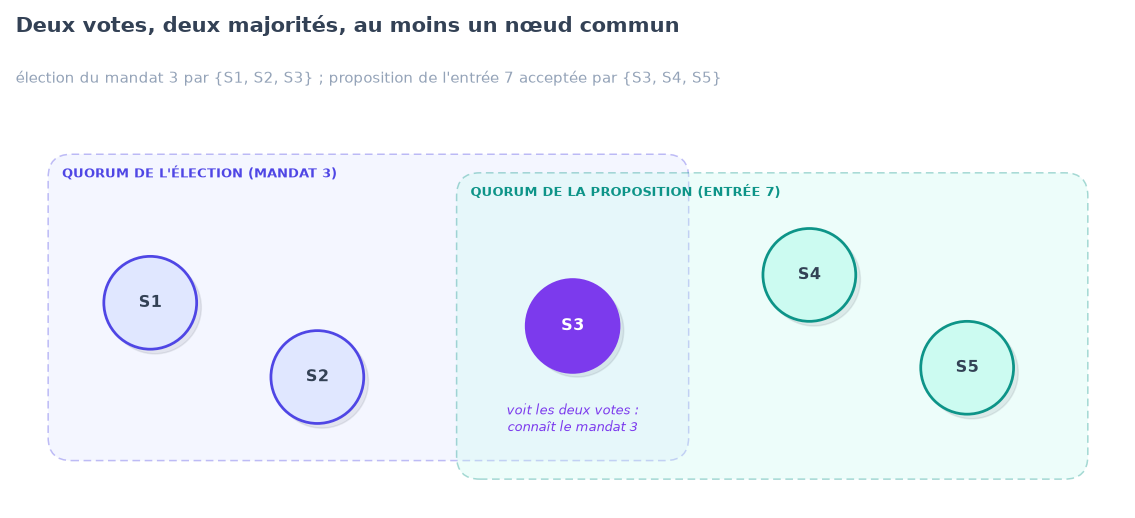

In [2]:
d = Diagram(12, 4.4, title="Deux votes, deux majorités, au moins un nœud commun",
            subtitle="élection du mandat 3 par {S1, S2, S3} ; proposition de l'entrée 7 acceptée par {S3, S4, S5}")
d.group(0.4, 0.5, 7.3, 3.8, "quorum de l'élection (mandat 3)", color=INDIGO)
d.group(4.8, 0.3, 11.6, 3.6, "quorum de la proposition (entrée 7)", color=TEAL)
for name, x, y, c in [("S1", 1.5, 2.2, INDIGO), ("S2", 3.3, 1.4, INDIGO), ("S3", 6.05, 1.95, VIOLET),
                      ("S4", 8.6, 2.5, TEAL), ("S5", 10.3, 1.5, TEAL)]:
    d.box(name, x, y, name, kind="circle", w=1.0, color=c, filled=name == "S3")
d.note(6.05, 0.95, "voit les deux votes :\nconnaît le mandat 3", color=VIOLET, fontsize=8.5)
d.show()

Ces deux tours de vote ressemblent superficiellement à la validation à deux phases
(cours 3), mais ce sont des protocoles très différents : dans un consensus,
**n'importe quel** nœud peut lancer une élection et il suffit d'un **quorum** de réponses ;
dans 2PC, seul le coordinateur sollicite des votes et il lui faut le **oui de tous** les
participants.

> **À retenir.** Un leader unique **par époque**, des époques croissantes, et des quorums
> d'élection et de proposition qui se recoupent : c'est la structure commune de Raft,
> Multi-Paxos, Zab et Viewstamped Replication.

## 3. Raft sur le simulateur : l'élection (section *Consensus algorithms and total order broadcast*)

Raft a été conçu pour être compréhensible. Chaque nœud est **suiveur**, **candidat** ou
**leader**, et conserve sur disque son mandat courant, son vote du mandat et son journal.

- Le leader envoie régulièrement des **battements** (`AppendEntries`, éventuellement
  vides). Un suiveur qui n'en reçoit pas pendant un **délai d'élection tiré au hasard**
  (ici entre 15 et 30 unités, contre 5 entre battements) devient candidat : il incrémente
  son mandat, vote pour lui et demande les votes des autres (`RequestVote`).
- Un nœud accorde **au plus un vote par mandat**, et seulement si le journal du candidat
  est **au moins aussi à jour** que le sien (section 6).
- Un candidat qui obtient une **majorité** devient leader ; un nœud qui voit un mandat plus
  grand que le sien redevient suiveur.

Le hasard des délais (cf. FLP, cours précédent) fait qu'en général un seul nœud se
réveille en premier et gagne avant que les autres ne se présentent. Observons la
première élection d'une grappe de cinq nœuds.

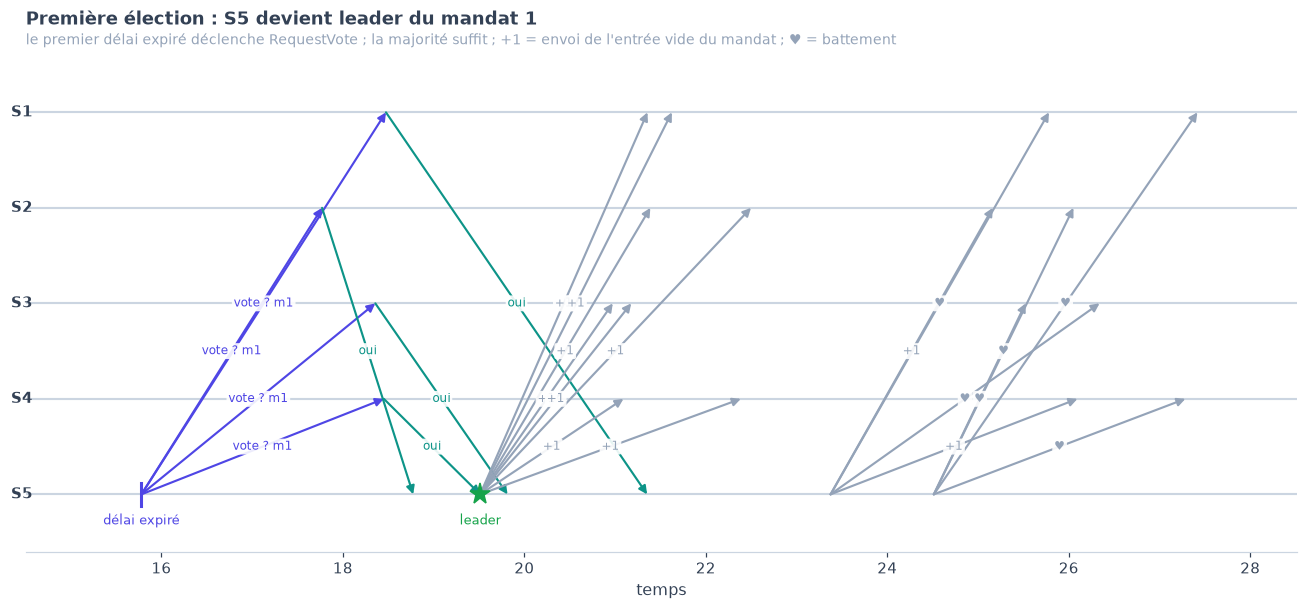

In [3]:
net, nodes, trace = cs.raft_cluster(5, seed=1, latency=(1.0, 3.0))
net.run(until=40)
t_el = cs.raft_leaders(trace)[0][0]
cand = [e for e in trace if e["kind"] == "candidate"][0]
col = {"RequestVote": INDIGO, "Vote": TEAL, "Append": GRAY, "AppendResp": GRAY}
def etiquette(d):
    m = d.msg
    if m[0] == "RequestVote":
        return f"vote ? m{m[1]}"
    if m[0] == "Vote":
        return "oui" if m[2] else "non"
    if m[0] == "Append":
        return "♥" if not m[5] else f"+{len(m[5])}"
    return ""
t0, t1 = cand["t"] - 1, t_el + 9
st = SpaceTime(list(nodes), t_max=t1, width=12, title=f"Première élection : {cand['node']} devient leader du mandat 1",
               subtitle="le premier délai expiré déclenche RequestVote ; la majorité suffit ; +1 = envoi de l'entrée vide du mandat ; ♥ = battement")
zoom(st, t0, t1)
st.from_trace([d for d in net.trace if t0 <= d.t_send <= t1 and d.msg[0] != "AppendResp"],
              color_of=lambda d: col[d.msg[0]], label_of=etiquette)
st.event(cand["node"], cand["t"], "délai expiré", kind="tick", color=INDIGO)
st.event(cand["node"], t_el, "leader", kind="star", color=GREEN)
st.show()

Le nœud dont le délai expire le premier demande les votes avec le mandat 1 ; les autres,
qui n'ont voté pour personne dans ce mandat, acceptent. Dès la 3e voix (la sienne
comprise), il est leader et envoie des battements qui réarment le délai des suiveurs.
Que se passe-t-il quand le leader meurt ? Tuons-le plusieurs fois et traçons la frise
des mandats.

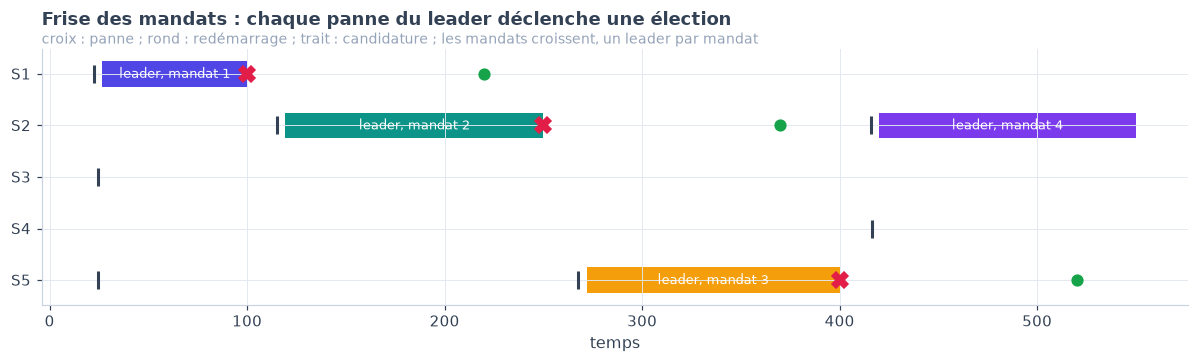

durées sans leader après chaque panne : [19.4, 21.9, 19.9]


In [4]:
net, nodes, trace = cs.raft_cluster(5, seed=3)
def tue_leader():
    x = leader_actuel(nodes)
    if x:
        net.crash(x)
        net.at(net.now + 120, net.recover, x)
for t in (100, 250, 400):
    net.at(t, tue_leader)
net.run(until=550)
fig, ax = plt.subplots(figsize=(11, 3.4))
names = list(nodes)
leaders = cs.raft_leaders(trace)
ends = [t for t, *_ in leaders[1:]] + [550]
for (t, x, term), te in zip(leaders, ends):
    crash = [e["t"] for e in trace if e["kind"] == "crash" and e["node"] == x and e["t"] > t]
    stop = min([te] + crash)
    c = TERM_COLORS[term % len(TERM_COLORS)]
    ax.barh(names.index(x), stop - t, left=t, color=c, height=0.5)
    ax.text((t + stop) / 2, names.index(x), f"leader, mandat {term}", ha="center", va="center", fontsize=8.5, color="white")
for e in trace:
    if e["kind"] == "crash":
        ax.plot(e["t"], names.index(e["node"]), "X", color=ROSE, ms=11)
    if e["kind"] == "recover":
        ax.plot(e["t"], names.index(e["node"]), "o", color=GREEN, ms=7)
    if e["kind"] == "candidate":
        ax.plot(e["t"], names.index(e["node"]), "|", color=SLATE, ms=12, mew=2)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("temps")
ax.set_title("Frise des mandats : chaque panne du leader déclenche une élection")
subtitle(ax, "croix : panne ; rond : redémarrage ; trait : candidature ; les mandats croissent, un leader par mandat")
plt.tight_layout(); plt.show()
indispo = []
for e in trace:
    if e["kind"] == "crash":
        nxt = [t for t, *_ in leaders if t > e["t"]]
        indispo.append(nxt[0] - e["t"])
print("durées sans leader après chaque panne :", [round(x, 1) for x in indispo])

Après chaque panne, il faut attendre l'expiration d'un délai d'élection (15 à 30 unités),
plus un aller-retour de votes : la grappe reste sans leader quelques dizaines d'unités.
Les nœuds redémarrés redeviennent de simples suiveurs du mandat courant.

> **À retenir.** Raft élit un leader par délais aléatoires et votes majoritaires, au plus
> un vote par nœud et par mandat. Une panne du leader coûte environ un délai d'élection
> d'indisponibilité.

## 4. Réplication du journal et validation par majorité

Le leader ajoute chaque commande d'un client à son journal, puis l'envoie aux suiveurs
(`AppendEntries`, avec l'indice et le mandat de l'entrée **précédente** : un suiveur dont
le journal ne concorde pas à cet endroit refuse, et le leader recule jusqu'au point
d'accord, puis écrase la suite divergente). Une entrée est **validée** (committed) dès
qu'elle est stockée sur une **majorité** ; le leader l'applique alors à sa machine à états
(ici un dictionnaire clé-valeur), répond au client et communique le nouvel indice de
validation aux suiveurs, qui l'appliquent à leur tour. C'est la seconde majorité de la
section 2 : une entrée confirmée au client survit à la panne du leader.

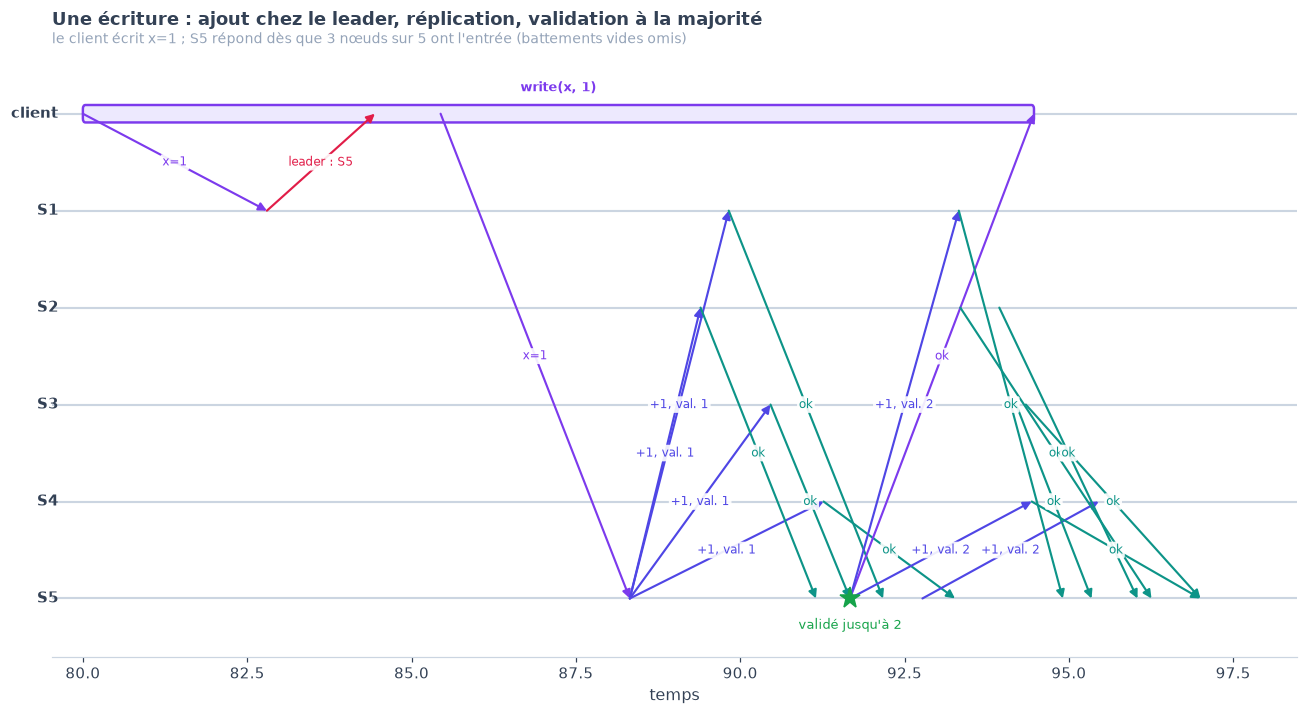

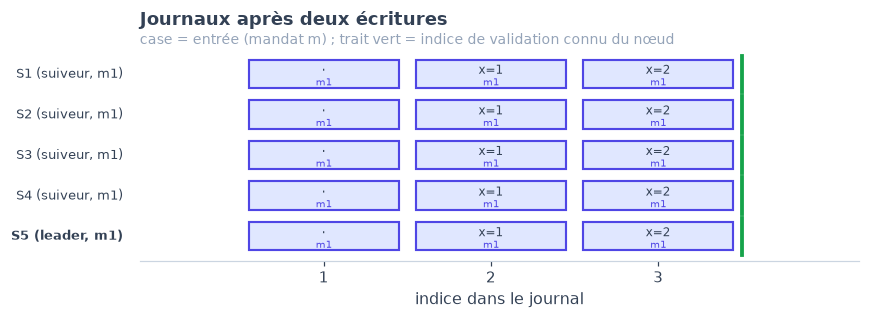

In [5]:
net, nodes, trace = cs.raft_cluster(5, seed=1, latency=(1.0, 3.0), heartbeat=12.0, election_timeout=(40.0, 60.0))
hist = []
net.add(cs.RaftClient("client", list(nodes), [(80, "write", 1), (30, "write", 2)], history=hist))
net.run(until=79.9)
t0 = net.now
net.run(until=105)
op = hist[0]
L = leader_actuel(nodes)
col = {"Submit": VIOLET, "Reply": VIOLET, "NotLeader": ROSE, "Append": INDIGO, "AppendResp": TEAL}
def etiq(d):
    m = d.msg
    if m[0] == "Submit":
        return f"x={m[2][2]}"
    if m[0] == "Reply":
        return "ok"
    if m[0] == "NotLeader":
        return f"leader : {m[2]}"
    if m[0] == "Append":
        return "♥" if not m[5] else f"+{len(m[5])}, val. {m[6]}"
    return "ok" if m[2] else "refus"
st = SpaceTime(["client"] + list(nodes), t_max=op.t_return + 4, width=12,
               title="Une écriture : ajout chez le leader, réplication, validation à la majorité",
               subtitle=f"le client écrit x=1 ; {L} répond dès que 3 nœuds sur 5 ont l'entrée (battements vides omis)")
zoom(st, t0, op.t_return + 4)
t_rep = min(d.t_send for d in net.trace if d.t_send >= t0 and d.msg[0] == "Append" and d.msg[5])
st.from_trace([d for d in net.trace if t0 <= d.t_send <= op.t_return and not (d.msg[0] == "Append" and not d.msg[5])
               and not (d.msg[0] == "AppendResp" and d.t_send < t_rep)], color_of=lambda d: col.get(d.msg[0], GRAY),
              label_of=etiq)
st.op("client", op.t_call, op.t_return, "write(x, 1)", color=VIOLET)
for e in trace:
    if e["kind"] == "commit" and t0 <= e["t"] <= op.t_return:
        st.event(e["node"], e["t"], f"validé jusqu'à {e['index']}", kind="star", color=GREEN)
st.show()
fig, ax = plt.subplots(figsize=(8, 3))
net.run(until=200)
dessine_journaux(nodes, ax, "Journaux après deux écritures", "case = entrée (mandat m) ; trait vert = indice de validation connu du nœud")
plt.tight_layout(); plt.show()

Le client a d'abord contacté un nœud qui n'était pas leader (s'il y a lieu, réponse « leader :
… ») puis le leader, qui a validé dès les trois premiers accusés de réception. La
première entrée de chaque journal est l'entrée vide (« · ») qu'un nouveau leader ajoute en
début de mandat pour faire valider sans attendre les entrées des mandats précédents.

> **À retenir.** Une entrée est validée quand une majorité la stocke ; le leader ne répond
> qu'à ce moment. La vérification de l'entrée précédente garantit que deux journaux qui
> concordent à un indice concordent sur tout ce qui précède.

## 5. Pannes et partitions : le leader isolé, les lectures linéarisables

Coupons le réseau : d'un côté le leader et un suiveur (minorité), de l'autre trois nœuds
(majorité). Un client resté du côté de l'ancien leader lui envoie une écriture.

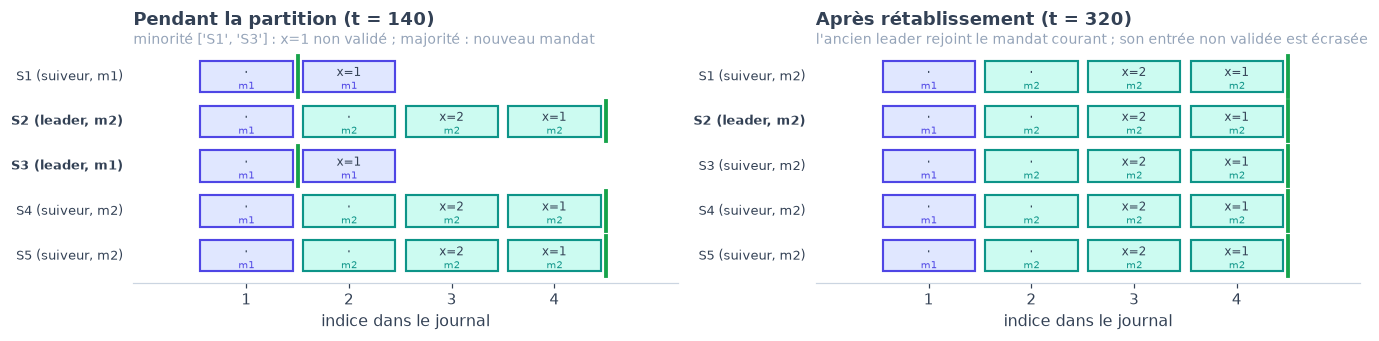

historique client : [('client B', 'w(2)', 110, 119), ('client A', 'w(1)', 61, 133)]
sûreté : {'mandats_a_deux_leaders': [], 'journaux_divergents': [], 'entrees_validees_effacees': 0, 'sur': True}


In [6]:
net, nodes, trace = cs.raft_cluster(5, seed=2)
hist = []
net.run(until=60)
old = leader_actuel(nodes)
others = [x for x in nodes if x != old]
minority, majority = {old, others[0]}, set(others[1:])
net.partition(minority, majority)
net.add(cs.RaftClient("client A", [old] + others, [(1, "write", 1)], history=hist, timeout=60))
net.add(cs.RaftClient("client B", others[1:] + [old, others[0]], [(50, "write", 2)], history=hist, timeout=60))
net.run(until=140)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
dessine_journaux(nodes, axes[0], "Pendant la partition (t = 140)", f"minorité {sorted(minority)} : x=1 non validé ; majorité : nouveau mandat")
net.heal()
net.run(until=320)
dessine_journaux(nodes, axes[1], "Après rétablissement (t = 320)", "l'ancien leader rejoint le mandat courant ; son entrée non validée est écrasée")
plt.tight_layout(); plt.show()
print("historique client :", [(o.client, cs.op_label(o), round(o.t_call), round(o.t_return)) for o in hist])
print("sûreté :", cs.raft_check_safety(nodes, trace))

Pendant la partition, l'ancien leader accepte l'écriture `x=1` mais **ne peut pas la
valider** (2 nœuds sur 5) : il ne répond pas au client. La majorité élit un nouveau leader
d'un mandat supérieur, qui valide `x=2`. Au rétablissement, l'ancien leader voit le mandat
supérieur, redevient suiveur, et son entrée non validée est **écrasée** : rien de ce qui
avait été confirmé n'est perdu. Le client A, sans réponse, a relancé sa requête après son
délai ; elle a fini par être validée par le nouveau leader. Attention : une relance peut
exécuter deux fois une commande si la première tentative avait en fait réussi
(l'idempotence règle ce problème, chapitre 11).

**Et les lectures ?** Pour des lectures linéarisables, le leader ne peut pas se contenter
de répondre avec son état local : il est peut-être **déchu** sans le savoir. Il doit
confirmer qu'il est toujours leader auprès d'un quorum, comme pour une écriture (ici, en
faisant passer la lecture par le journal ; etcd utilise une variante plus légère) ; ZooKeeper, lui, offre une opération `sync` à faire avant une lecture qui doit être fraîche.
Comparons les deux modes avec le vérificateur du cours 1 : pendant la partition, un
client lit à travers l'ancien leader, un autre écrit à travers le nouveau.

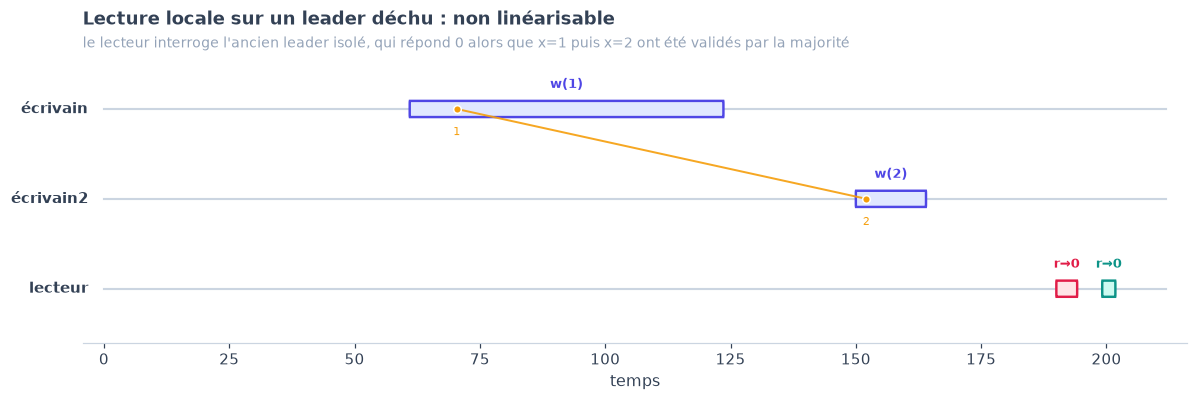

,historiques_linéarisables,latence_moyenne_lecture
mode,,
local,0.033,4.059
log,1.000,32.681


In [7]:
def scenario_lecture(read_mode, seed):
    net, nodes, trace = cs.raft_cluster(5, seed=seed, read_mode=read_mode)
    hist = []
    net.run(until=60)
    old = leader_actuel(nodes)
    others = [x for x in nodes if x != old]
    net.add(cs.RaftClient("écrivain", others[1:], [(1, "write", 1)], history=hist, timeout=40))
    net.run(until=90)
    net.partition({old, others[0]}, set(others[1:]))
    net.add(cs.RaftClient("écrivain2", others[1:], [(60, "write", 2)], history=hist, timeout=40))
    net.add(cs.RaftClient("lecteur", [old] + others, [(100, "read", None), (5, "read", None)], history=hist, timeout=40))
    net.run(until=400)
    hist.sort(key=lambda o: o.t_call)
    return hist

rows = []
for mode in ("local", "log"):
    for seed in range(30):
        h = scenario_lecture(mode, seed)
        res = cs.check_linearizable(h)
        lect = [o for o in h if o.kind == "read"]
        rows.append(dict(mode=mode, linéarisable=res.ok, latence_lecture=np.mean([o.t_return - o.t_call for o in lect])))
R = pd.DataFrame(rows)
h_bad = scenario_lecture("local", 0)
res_bad = cs.check_linearizable(h_bad)
st = cs.plot_history(h_bad, title="Lecture locale sur un leader déchu : non linéarisable",
                     subtitle="le lecteur interroge l'ancien leader isolé, qui répond 0 alors que x=1 puis x=2 ont été validés par la majorité",
                     result=res_bad, highlight=res_bad.blocking(h_bad)[:1], width=11)
st.show()
R.groupby("mode").agg(historiques_linéarisables=("linéarisable", "mean"), latence_moyenne_lecture=("latence_lecture", "mean"))

En lecture **locale**, l'ancien leader isolé répond avec sa valeur périmée : sur la
plupart des 30 graines, l'historique est **non linéarisable**. En lecture **par le
journal**, le leader déchu ne peut pas faire valider la lecture : le client attend, puis
relance vers un autre nœud et obtient la valeur fraîche. Le prix est la latence : un
aller-retour de quorum par lecture, plus les relances pendant la panne.

> **À retenir.** Une minorité isolée ne peut rien valider : pas de cerveau divisé, pas de
> perte d'écriture confirmée. Mais un leader déchu peut encore **répondre** : pour être
> linéarisables, les lectures doivent elles aussi passer par un quorum.

## 6. Le nouveau leader doit être à jour

La structure « une élection, puis un vote par entrée » est commune à Raft, Multi-Paxos,
Viewstamped Replication et Zab ; ils diffèrent dans les détails, là où se cachent les
bogues. Par exemple, un nouveau leader doit **respecter** les entrées que l'ancien a déjà
fait valider :

- **Raft** n'élit qu'un candidat dont le journal est **au moins aussi à jour** que celui
  d'une majorité : un nœud refuse son vote si le dernier mandat du journal du candidat est
  plus petit que le sien, ou égal mais avec un journal plus court. Comme une entrée validée
  est sur une majorité et que l'élection demande une majorité, un nœud au moins refusera
  tout candidat qui ne l'a pas ;
- **Paxos** laisse n'importe quel nœud devenir leader, mais l'oblige à **mettre son journal
  à jour** auprès des autres avant d'ajouter ses propres entrées.

Autre subtilité : le sort des entrées proposées par l'ancien leader mais pas encore
validées (Raft ne valide par comptage que les entrées **de son propre mandat** ; les
anciennes sont validées indirectement). Mesurons l'effet de la règle d'élection : on fait
valider une entrée par trois nœuds sur cinq, on arrête le leader, et l'on regarde qui
peut être élu.

In [8]:
net, nodes, trace = cs.raft_cluster(5, seed=5)
hist = []
net.run(until=60)
L = leader_actuel(nodes)
autres = [x for x in nodes if x != L]
retard = autres[:2]                        # deux nœuds coupés : ils ne verront pas l'entrée
for x in retard:
    net.partition({x}, set(nodes) - {x})
net.add(cs.RaftClient("client", [L], [(1, "write", 7)], history=hist, timeout=50))
net.run(until=100)
etat = []
for x in nodes:
    li, lt = nodes[x]._last()
    etat.append(dict(nœud=x, rôle=nodes[x].role, mandat=nodes[x].term, dernier_indice=li, dernier_mandat_du_journal=lt,
                     a_x7=any(e.cmd == ("set", "x", 7) for e in nodes[x].log)))
t_crash = net.now
net.heal()
net.crash(L)                               # le leader tombe juste après avoir validé x=7
net.run(until=400)
cands = [e for e in trace if e["kind"] == "candidate" and e["t"] > t_crash]
gagnants = [(x, t) for tt, x, t in cs.raft_leaders(trace) if tt > t_crash]
print(f"x=7 confirmé au client : {hist[0].result if hist else 'non'} ; retardataires : {retard}")
print("candidatures après la panne :", [(e["node"], e["term"]) for e in cands])
print("élu :", gagnants, "; le nouveau leader a x=7 :", any(e.cmd == ("set", "x", 7) for e in nodes[gagnants[0][0]].log))
pd.DataFrame(etat)

x=7 confirmé au client : ok ; retardataires : ['S1', 'S2']
candidatures après la panne : [('S1', 4), ('S1', 5), ('S5', 6)]
élu : [('S5', 6)] ; le nouveau leader a x=7 : True


,nœud,rôle,mandat,dernier_indice,dernier_mandat_du_journal,a_x7
0,S1,candidate,3,1,1,False
1,S2,candidate,3,1,1,False
2,S3,follower,1,2,1,True
3,S4,leader,1,2,1,True
4,S5,follower,1,2,1,True


Au moment de la panne, seuls trois nœuds (dont le leader) détiennent `x=7`. Les deux
retardataires, isolés, ont multiplié les candidatures sans succès : leur **mandat** est
plus grand que celui des autres, mais leur **journal** plus court. Après le rétablissement,
leurs candidatures obligent les autres à passer au mandat supérieur, mais les nœuds qui
ont `x=7` leur refusent leur vote : ils ne peuvent pas réunir trois voix. Le nouveau
leader est nécessairement un nœud qui détient l'entrée. L'exercice 9.9 supprime
cette règle (`check_log=False`) et montre qu'une écriture confirmée au client peut alors
**disparaître**.

**Reconfiguration.** Les algorithmes supposent dans leur forme de base un ensemble **fixe**
de nœuds votants. En pratique, il faut en ajouter ou en retirer (ajouter une région,
migrer d'un site à un autre en ajoutant les nouveaux nœuds puis en retirant les anciens) :
des extensions de **reconfiguration** le permettent sans casser les garanties.

> **À retenir.** Un nouveau leader doit détenir toutes les entrées validées : Raft le
> garantit à l'élection (journal au moins aussi à jour qu'une majorité), Paxos par une
> mise à jour préalable. Le relâcher accélère la reprise mais peut perdre des données.

## 7. Avantages et limites du consensus (section *Limitations of consensus*)

Le consensus est une percée : c'est la « réplication à leader unique bien faite », avec
bascule automatique, sans perte de données validées ni cerveau divisé, malgré tous les
problèmes du chapitre 8. Un système qui bascule automatiquement **sans**
algorithme de consensus éprouvé est probablement dangereux. (Utiliser un tel algorithme
ne garantit pas que tout le système est correct, mais c'est un bon début.) Il a pourtant
des coûts.

**Une majorité stricte, et chaque opération coûte un quorum.** Trois nœuds pour tolérer
une panne, cinq pour deux. Chaque écriture attend un quorum : ajouter des nœuds
n'augmente pas le débit, au contraire. Mesurons la latence d'écriture et le nombre de
messages par écriture selon la taille de la grappe.

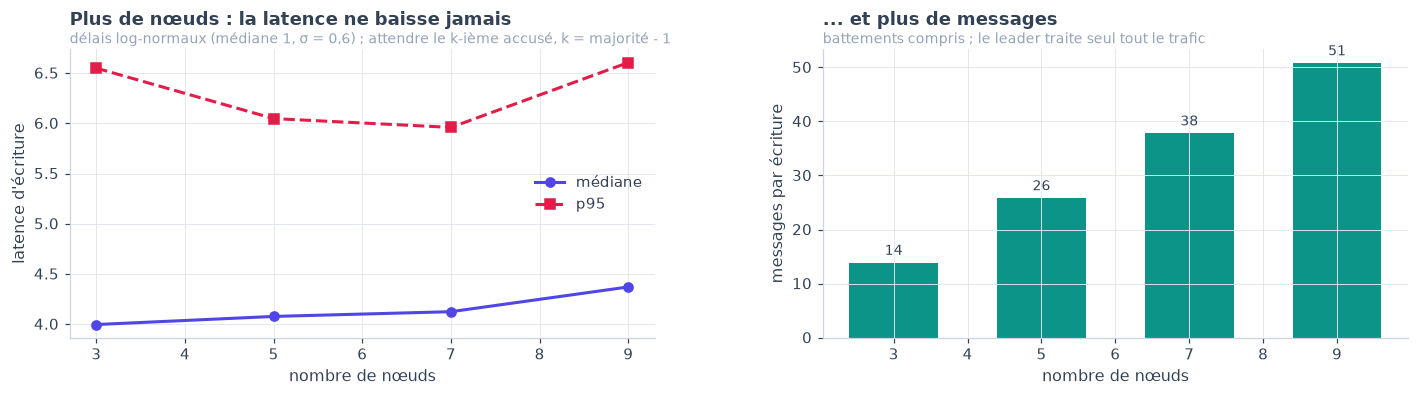

,latence,p95,messages
n,,,
3,3.996,6.549,13.867
5,4.077,6.047,25.817
7,4.124,5.959,37.792
9,4.371,6.605,50.775


In [9]:
rows = []
for n_ in (3, 5, 7, 9):
    for seed in range(4):
        net, nodes, trace = cs.raft_cluster(n_, seed=seed, latency=cs.lognormal_latency(1.0, 0.6))
        hist = []
        script = [(60, "write", 0)] + [(0.5, "write", k) for k in range(1, 30)]
        net.add(cs.RaftClient("client", list(nodes), script, history=hist, timeout=40))
        net.run(until=59)
        m0 = len(net.trace)
        net.run(until=2000)
        lat = [o.t_return - o.t_call for o in hist[1:]]
        span = hist[-1].t_return - hist[1].t_call
        rows.append(dict(n=n_, latence=np.median(lat), p95=np.percentile(lat, 95),
                         messages=(len([d for d in net.trace[m0:] if d.t_send <= hist[-1].t_return])) / len(hist)))
C = pd.DataFrame(rows).groupby("n").mean()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.7))
ax.plot(C.index, C.latence, "o-", color=INDIGO, label="médiane")
ax.plot(C.index, C.p95, "s--", color=ROSE, label="p95")
ax.set_xlabel("nombre de nœuds"); ax.set_ylabel("latence d'écriture")
ax.set_title("Plus de nœuds : la latence ne baisse jamais")
subtitle(ax, "délais log-normaux (médiane 1, σ = 0,6) ; attendre le k-ième accusé, k = majorité - 1")
ax.legend()
ax2.bar(C.index, C.messages, color=TEAL, width=1.2)
annotate_bars(ax2, "{:.0f}")
ax2.set_xlabel("nombre de nœuds"); ax2.set_ylabel("messages par écriture")
ax2.set_title("... et plus de messages")
subtitle(ax2, "battements compris ; le leader traite seul tout le trafic")
plt.tight_layout(); plt.show()
C

La latence médiane augmente légèrement (de 4,0 à 4,4 délais médians de 3 à 9 nœuds) :
attendre le $k$-ième accusé parmi $n - 1$, avec $k$ proche de la moitié, revient à attendre
à peu près le délai médian, quel que soit $n$. Elle ne **baisse** en tout cas jamais :
ajouter des nœuds n'accélère rien. Le nombre de messages, lui, croît **linéairement**
(de 14 à 51 par écriture), et c'est le leader qui les émet et les reçoit tous : il devient
le goulot d'étranglement, et le débit maximal baisse avec la taille de la grappe. On ne monte pas en charge en ajoutant des
nœuds à une grappe de consensus ; on la garde petite (3 ou 5 nœuds) et l'on partitionne
les données entre plusieurs grappes. Si une partition réseau isole des nœuds, seule la
majorité progresse.

**Des délais à régler.** Le consensus détecte les pannes par délais d'expiration. Trop
longs, la reprise est lente ; trop courts, des élections inutiles se succèdent (un
leader vivant mais lent est destitué), au point que le système peut passer plus de temps à
élire qu'à travailler. C'est d'autant plus délicat que les délais réseau varient
(grappes réparties entre régions). Simulons 2 000 unités de temps **sans aucune panne**,
avec des délais réseau log-normaux de plus en plus dispersés, pour deux réglages.

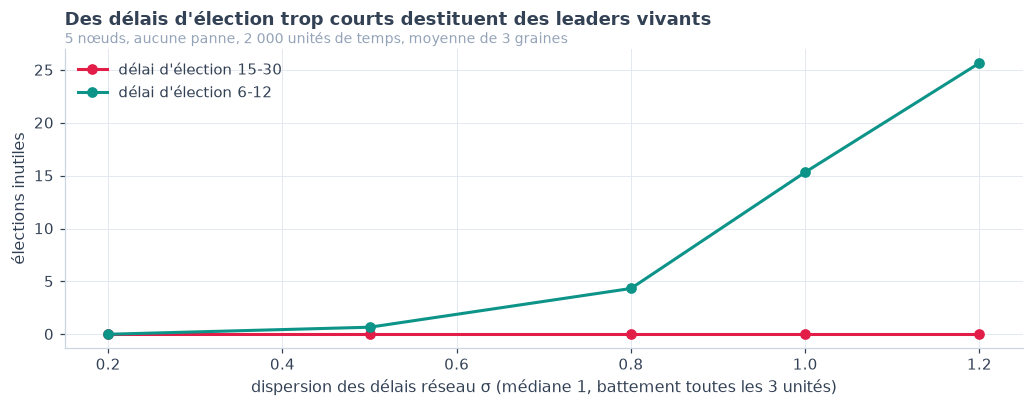

réglage,délai d'élection 15-30,délai d'élection 6-12
sigma,,
0.2,0.0,0.000
0.5,0.0,0.667
0.8,0.0,4.333
1.0,0.0,15.333
1.2,0.0,25.667


In [10]:
rows = []
for sigma in (0.2, 0.5, 0.8, 1.0, 1.2):
    for et, lab in [((6.0, 12.0), "délai d'élection 6-12"), ((15.0, 30.0), "délai d'élection 15-30")]:
        for seed in range(3):
            net, nodes, trace = cs.raft_cluster(5, seed=seed, latency=cs.lognormal_latency(1.0, sigma),
                                                election_timeout=et, heartbeat=3.0)
            net.run(until=2000)
            rows.append(dict(sigma=sigma, réglage=lab, élections=len(cs.raft_leaders(trace)) - 1))
E = pd.DataFrame(rows).groupby(["sigma", "réglage"]).élections.mean().unstack()
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for c, col_ in zip(E.columns, [ROSE, TEAL]):
    ax.plot(E.index, E[c], "o-", color=col_, label=c)
ax.set_xlabel("dispersion des délais réseau σ (médiane 1, battement toutes les 3 unités)")
ax.set_ylabel("élections inutiles")
ax.set_title("Des délais d'élection trop courts destituent des leaders vivants")
subtitle(ax, "5 nœuds, aucune panne, 2 000 unités de temps, moyenne de 3 graines")
ax.legend()
plt.tight_layout(); plt.show()
E

Avec des délais réseau réguliers, aucun réglage ne provoque d'élection inutile. Quand la
dispersion augmente, les battements en retard déclenchent des élections avec le réglage
court, beaucoup plus qu'avec le réglage long, qui reprendra en revanche plus lentement
après une vraie panne (exercice 9.10).

**Un lien défaillant.** Le consensus peut être très sensible à certains problèmes de
réseau. Raft a des cas limites désagréables : si tout le réseau fonctionne sauf **un**
lien, durablement coupé, le pouvoir peut faire des allers-retours entre deux nœuds, ou le
leader être sans cesse contraint d'abdiquer. Coupons le lien entre le leader et un
suiveur.

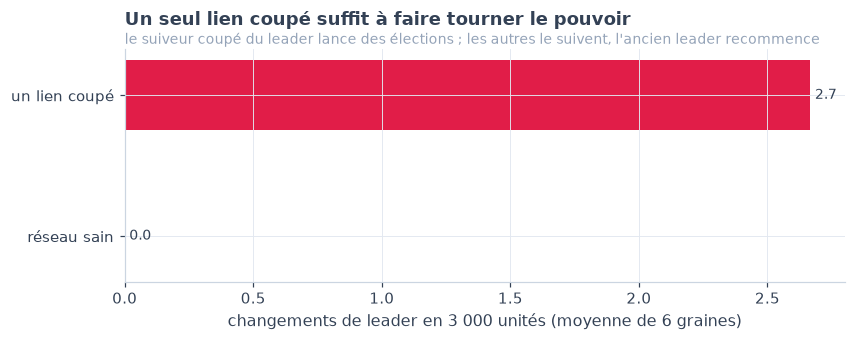

,changements,mandat_final
lien,,
réseau sain,0.000,1.0
un lien coupé,2.667,5.5


In [11]:
rows = []
for flaky in (False, True):
    for seed in range(6):
        net, nodes, trace = cs.raft_cluster(5, seed=seed)
        net.run(until=60)
        L = leader_actuel(nodes)
        o = [x for x in nodes if x != L][0]
        if flaky:
            net.block(L, o); net.block(o, L)
        net.run(until=3000)
        rows.append(dict(lien=("un lien coupé" if flaky else "réseau sain"), changements=len(cs.raft_leaders(trace)) - 1,
                         mandat_final=max(n.term for n in nodes.values())))
F = pd.DataFrame(rows).groupby("lien").mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(F.index, F.changements, color=[TEAL, ROSE], height=0.5)
annotate_bars(ax, "{:.1f}")
ax.set_xlabel("changements de leader en 3 000 unités (moyenne de 6 graines)")
ax.set_title("Un seul lien coupé suffit à faire tourner le pouvoir")
subtitle(ax, "le suiveur coupé du leader lance des élections ; les autres le suivent, l'ancien leader recommence")
plt.tight_layout(); plt.show()
F

Avec un réseau sain, le premier leader garde le pouvoir. Avec un seul lien coupé, le
suiveur qui n'entend plus le leader se présente avec un mandat supérieur ; s'il est élu,
c'est l'ancien leader qui ne l'entend plus, et ainsi de suite : le pouvoir tourne, et
chaque changement coûte une période sans leader.

> **À retenir.** Le consensus offre une bascule sûre, au prix d'une majorité stricte,
> d'un quorum par opération (pas de montée en charge par ajout de nœuds), de délais
> d'expiration délicats à régler et d'une sensibilité à certaines pannes réseau partielles.

## Synthèse

- Les algorithmes de consensus pratiques sont de la **réplication à leader unique** avec
  élection automatique : un leader unique **par mandat**, des mandats croissants.
- Deux votes majoritaires qui **se recoupent** (élection, puis chaque entrée) garantissent
  qu'une entrée validée survit et qu'un leader déchu ne peut rien valider.
- Notre implémentation de Raft le confirme : élections par délais aléatoires, journaux
  réconciliés, aucune perte d'écriture validée malgré pannes et partitions ; les
  **lectures** doivent aussi passer par un quorum pour rester linéarisables.
- Un nouveau leader doit être **à jour** (règle d'élection de Raft).
- Coûts : majorité stricte, latence d'un quorum par opération, pas de montée en charge par
  ajout de nœuds, délais à régler, sensibilité aux liens défaillants.

Liens : la réplication à leader unique et la bascule au chapitre 5, les
délais, pauses et jetons de clôture au chapitre 8, les journaux au chapitre
11. Le cours suivant étudie les **services de coordination** (ZooKeeper, etcd)
bâtis sur ces algorithmes.